# 5. Признаки в окнах: tsfresh там, где нужен прогноз

В предыдущих ноутбуках паспорт считался **один раз на ряд**: 10–777 статистик по всей истории,
и модель получала их как постоянные признаки сегмента. Но у такой схемы есть очевидное
ограничение — паспорт не меняется во времени, поэтому он ничего не говорит о том,
**что происходит прямо сейчас**.

Альтернатива — считать те же статистики **в каждом окне**: для каждой даты $t$ берём
последние $W$ точек, считаем `tsfresh`-признаки окна и прогнозируем значение через $H$ дней.

Сквозной вопрос: **что даёт перенос tsfresh из «паспорта» в «окна», кроме роста счёта за вычисления?**

План: постановка → механика `roll_time_series` → проверка признаков руками → два набора
признаков → обучение при $H = 365$ → ловушка годового горизонта → короткий горизонт $W = 28$ →
цена → итоги.

In [2]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error
from tsfresh import extract_features, select_features
from tsfresh.feature_extraction import EfficientFCParameters, MinimalFCParameters
from tsfresh.utilities.dataframe_functions import impute, roll_time_series

from common import read_data

warnings.simplefilter("ignore")
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True

HORIZON = 365  
WINDOW = 28    # окно для экспериментов на коротком горизонте

## 0. Постановка


точек: 2191 | 2010-01-01 … 2015-12-31
среднее: 325.6 | std: 64.26549026473214 | CV: 0.19735112949527261


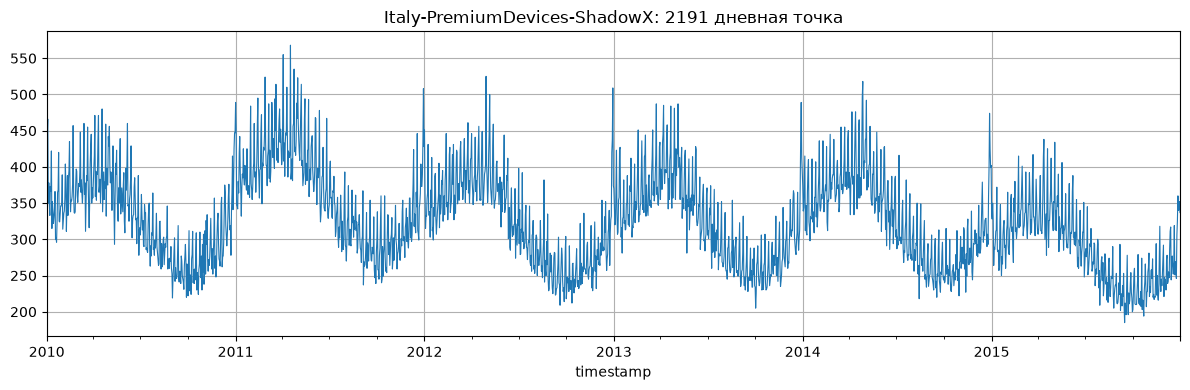

In [4]:
data = read_data("daily_sales_train.csv.gz", parse_dates=["timestamp"])
segment = "Italy-PremiumDevices-ShadowX"

df = data[data["segment"] == segment][["segment", "timestamp", "target"]].reset_index(drop=True)
s = df.set_index("timestamp")["target"]

print("точек:", len(df), "|", df["timestamp"].min().date(), "…", df["timestamp"].max().date())
print("среднее:", s.mean().round(1), "| std:", s.std(), "| CV:", (s.std() / s.mean()))
df.set_index("timestamp")["target"].plot(lw=0.8)
plt.title(f"{segment}: 2191 дневная точка")
plt.tight_layout()

Ряд выглядит гладким, но это обман зрения из-за плотности точек: недельный цикл виден,
а коэффициент вариации 0.2 говорит, что день ото дня значение меняется заметно.
Именно поэтому прогноз на год вперёд — отдельная, гораздо более трудная задача, чем прогноз
на неделю.

## 1. Схема «признаки окна → таргет через H дней»

Главное отличие от паспорта: признак теперь принадлежит **не ряду, а паре (ряд, дата)**.

```
       t-W+1 … t          t+H
─────────┬────────────┬──────────────┬────────
         [ окно W ]   ↑              ↑
         признаки     last_date      таргет
```


## 2. Механика: `roll_time_series`

`tsfresh` ожидает long-таблицу `[id, time, value]`, где `id` — один ряд. Чтобы посчитать
статистики в окнах, `roll_time_series` размножает ряд: каждая строка попадает во все окна,
которые её содержат, а в колонке `id` появляется пара `(segment, дата конца окна)`.

Параметры:
- `rolling_direction=1` — окно «смотрит в прошлое» относительно `id`-даты (двигаем дату вперёд);
- `max_timeshift` — максимальная длина окна, `min_timeshift` — минимальная.

In [5]:
t0 = time.perf_counter()
rolled = roll_time_series(
    df,
    column_id="segment",
    column_sort="timestamp",
    rolling_direction=1,
    min_timeshift=WINDOW - 21,  # окно от 8…
    max_timeshift=WINDOW,       # …до 28 точек
    n_jobs=0,
)
print(f"roll_time_series: {time.perf_counter() - t0:.1f} с, окон: {rolled['id'].nunique()}")
rolled.head()

Rolling: 100%|█████████████████████████████████| 2191/2191 [00:00<00:00, 2669.54it/s]


roll_time_series: 0.9 с, окон: 2184


,segment,timestamp,target,id
0,Italy-PremiumDevices-ShadowX,2010-01-01,429.0,"(Italy-PremiumDevices-ShadowX, 2010-01-08 00:0..."
1,Italy-PremiumDevices-ShadowX,2010-01-02,443.0,"(Italy-PremiumDevices-ShadowX, 2010-01-08 00:0..."
2,Italy-PremiumDevices-ShadowX,2010-01-03,466.0,"(Italy-PremiumDevices-ShadowX, 2010-01-08 00:0..."
3,Italy-PremiumDevices-ShadowX,2010-01-04,350.0,"(Italy-PremiumDevices-ShadowX, 2010-01-08 00:0..."
4,Italy-PremiumDevices-ShadowX,2010-01-05,378.0,"(Italy-PremiumDevices-ShadowX, 2010-01-08 00:0..."


В таблице каждая строка — точка ряда внутри окна, а `id` — это метка окна. Посмотрим,
как устроено одно окно: все строки с одинаковым `id` и есть его содержимое.

In [6]:
example_id = (segment, pd.Timestamp("2015-06-30"))
window = rolled[rolled["id"] == example_id]
print("точек в окне:", len(window), "|", window["timestamp"].min().date(), "…", window["timestamp"].max().date())
window

точек в окне: 29 | 2015-06-02 … 2015-06-30


,segment,timestamp,target,id
57740,Italy-PremiumDevices-ShadowX,2015-06-02,280.0,"(Italy-PremiumDevices-ShadowX, 2015-06-30 00:0..."
57741,Italy-PremiumDevices-ShadowX,2015-06-03,309.0,"(Italy-PremiumDevices-ShadowX, 2015-06-30 00:0..."
57742,Italy-PremiumDevices-ShadowX,2015-06-04,308.0,"(Italy-PremiumDevices-ShadowX, 2015-06-30 00:0..."
57743,Italy-PremiumDevices-ShadowX,2015-06-05,313.0,"(Italy-PremiumDevices-ShadowX, 2015-06-30 00:0..."
57744,Italy-PremiumDevices-ShadowX,2015-06-06,366.0,"(Italy-PremiumDevices-ShadowX, 2015-06-30 00:0..."
57745,Italy-PremiumDevices-ShadowX,2015-06-07,388.0,"(Italy-PremiumDevices-ShadowX, 2015-06-30 00:0..."
57746,Italy-PremiumDevices-ShadowX,2015-06-08,303.0,"(Italy-PremiumDevices-ShadowX, 2015-06-30 00:0..."
57747,Italy-PremiumDevices-ShadowX,2015-06-09,302.0,"(Italy-PremiumDevices-ShadowX, 2015-06-30 00:0..."
57748,Italy-PremiumDevices-ShadowX,2015-06-10,293.0,"(Italy-PremiumDevices-ShadowX, 2015-06-30 00:0..."
57749,Italy-PremiumDevices-ShadowX,2015-06-11,310.0,"(Italy-PremiumDevices-ShadowX, 2015-06-30 00:0..."


Окна перекрываются: соседние даты делят почти все точки. Отсюда сразу два следствия —
признаки соседних строк очень похожи (модель будет учиться на почти дублирующихся данных),
а вычислять их приходится заново для каждой даты.

## 3. Что именно считают признаки: проверяем руками

Прежде чем доверять модели, убедимся, что признаки окна — это те же самые статистики,
которые мы привыкли считать сами.

In [7]:
X_check = extract_features(
    rolled.drop(columns=["segment"]),
    default_fc_parameters=MinimalFCParameters(),
    column_id="id",
    column_sort="timestamp",
    column_value="target",
    impute_function=None,
    show_warnings=False,
    n_jobs=0,
)
print("признаков:", X_check.shape[1], "|", list(X_check.columns))

values = window["target"].to_numpy()
checks = {
    "target__mean": values.mean(),
    "target__maximum": values.max(),
    "target__minimum": values.min(),
    "target__standard_deviation": values.std(ddof=0),
    "target__length": len(values),
}
for col, manual in checks.items():
    got = float(X_check.loc[example_id, col])
    print(f"{col:28s} вручную={manual:8.3f}  tsfresh={got:8.3f}  совпало={np.isclose(manual, got)}")

Feature Extraction: 100%|██████████████████████| 2184/2184 [00:00<00:00, 7958.72it/s]

признаков: 10 | ['target__sum_values', 'target__median', 'target__mean', 'target__length', 'target__standard_deviation', 'target__variance', 'target__root_mean_square', 'target__maximum', 'target__absolute_maximum', 'target__minimum']
target__mean                 вручную= 301.759  tsfresh= 301.759  совпало=True
target__maximum              вручную= 388.000  tsfresh= 388.000  совпало=True
target__minimum              вручную= 248.000  tsfresh= 248.000  совпало=True
target__standard_deviation   вручную=  32.409  tsfresh=  32.409  совпало=True
target__length               вручную=  29.000  tsfresh=  29.000  совпало=True


Совпало по всем пяти — магии нет, `MinimalFCParameters` это 10 базовых статистик:
сумма, медиана, среднее, длина, стандартное отклонение, дисперсия, RMS, максимум,
модуль-максимум и минимум. Все они, кроме `length`, зависят от **уровня** ряда

## 4. Два набора признаков

- `MinimalFCParameters` — 10 статистик, считаются за доли секунды;
- `EfficientFCParameters` — 777 признаков (тренды, энтропии, вейвлеты, автокорреляции…),
  требуют импутации `NaN`.

In [8]:
t0 = time.perf_counter()
X_min = extract_features(
    rolled.drop(columns=["segment"]),
    default_fc_parameters=MinimalFCParameters(),
    column_id="id", column_sort="timestamp", column_value="target",
    impute_function=impute, show_warnings=False, n_jobs=0,
)
t_min = time.perf_counter() - t0

t0 = time.perf_counter()
X_eff = extract_features(
    rolled.drop(columns=["segment"]),
    default_fc_parameters=EfficientFCParameters(),
    column_id="id", column_sort="timestamp", column_value="target",
    impute_function=impute, show_warnings=False, n_jobs=0,
)
t_eff = time.perf_counter() - t0

print(f"Minimal:   {X_min.shape}, {t_min:.1f} с")
print(f"Efficient: {X_eff.shape}, {t_eff:.1f} с")

Feature Extraction: 100%|████████████████████████| 2184/2184 [00:50<00:00, 43.32it/s]


Minimal:   (2184, 10), 0.4 с
Efficient: (2184, 777), 52.5 с


Индекс `tsfresh` — `MultiIndex` из пары `(segment, last_date)`. Дата ряда нам не нужна
(ряд один), поэтому оставляем только дату конца окна: она и будет ключом, по которому
приклеивается таргет.

In [9]:
for name in ("X_min", "X_eff"):
    X = locals()[name]
    X.index = pd.DatetimeIndex([ts for _, ts in X.index], name="last_date")
    locals()[name] = X

X_min.head(3).T

last_date,2010-01-08,2010-01-09,2010-01-10
target__sum_values,3122.000000,3488.000000,3910.000000
target__median,375.500000,373.000000,375.500000
target__mean,390.250000,387.555556,391.000000
target__length,8.000000,9.000000,10.000000
target__standard_deviation,46.080771,44.108732,43.102204
target__variance,2123.437500,1945.580247,1857.800000
target__root_mean_square,392.961194,390.057546,393.368529
target__maximum,466.000000,466.000000,466.000000
target__absolute_maximum,466.000000,466.000000,466.000000
target__minimum,333.000000,333.000000,333.000000


## 5. Таргет: сдвиг на горизонт

Самый простой способ ошибиться — приклеить к признакам окна значение **последней точки окна**
вместо значения **через $H$ дней**. Сделаем явно: переносим ряд на $-H$ дней, и значение с датой $t$
становится таргетом для признаков, посчитанных на окне, заканчивающемся в $t$.

In [10]:
y = pd.Series(
    s.reindex(X_min.index + pd.Timedelta(days=HORIZON)).to_numpy(),
    index=X_min.index,
    name="target",
)
print("окон с известным таргетом:", int(y.notna().sum()), "из", len(y))
print("последняя дата окна с таргетом:", y.dropna().index.max().date())

окон с известным таргетом: 1819 из 2184
последняя дата окна с таргетом: 2014-12-31


In [18]:
X_min.index.max()

Timestamp('2015-12-31 00:00:00')

In [20]:
y.index.max()

Timestamp('2015-12-31 00:00:00')

In [22]:
s.reindex(X_min.index + pd.Timedelta(days=HORIZON)).to_numpy()

array([419., 442., 392., ...,  nan,  nan,  nan])

In [51]:
X_min.index + pd.Timedelta(days=HORIZON)

DatetimeIndex(['2011-01-08', '2011-01-09', '2011-01-10', '2011-01-11',
               '2011-01-12', '2011-01-13', '2011-01-14', '2011-01-15',
               '2011-01-16', '2011-01-17',
               ...
               '2016-12-21', '2016-12-22', '2016-12-23', '2016-12-24',
               '2016-12-25', '2016-12-26', '2016-12-27', '2016-12-28',
               '2016-12-29', '2016-12-30'],
              dtype='datetime64[ns]', name='last_date', length=2184, freq=None)

В конце ряда таргета нет: окна, заканчивающиеся в 2015 году, предсказывали бы значения
в 2016-м, которых в данных не существует. Поэтому последние окна отбрасываем — это
не потеря, а единственно возможный вариант при годовом горизонте.

## 6. Обучение при $H = 365$

train — всё, кроме последних $2H$ окон, test — окна
в интервале $[-2H, -H)$. Модель — `CatBoostRegressor`. Метрики — MAE и MAPE.

In [11]:
def evaluate(X: pd.DataFrame, horizon: int, season: int, select: bool = False) -> dict:
    """Одиночный сплит как в Part_2: test — окна, предсказывающие последний горизонт."""
    n = len(X)
    train, test = X.iloc[: n - 2 * horizon], X.iloc[n - 2 * horizon: n - horizon]

    y_all = pd.Series(
        s.reindex(X.index + pd.Timedelta(days=horizon)).to_numpy(), index=X.index
    )
    y_train, y_test = y_all.reindex(train.index), y_all.reindex(test.index)
    keep_train, keep_test = y_train.notna().to_numpy(), y_test.notna().to_numpy()
    train, test, y_train, y_test = train[keep_train], test[keep_test], y_train[keep_train], y_test[keep_test]

    kept = train.shape[1]
    if select:
        cols = select_features(train, y_train, ml_task="regression", n_jobs=0).columns
        train, test = train[cols], test[cols]
        kept = len(cols)

    t0 = time.perf_counter()
    model = CatBoostRegressor(iterations=200, depth=6, random_seed=0, verbose=0)
    model.fit(train, y_train)
    pred = model.predict(test)

    naive = s.reindex(test.index + pd.Timedelta(days=horizon - season)).to_numpy()
    return {
        "признаков": kept,
        "train": len(train),
        "test": len(test),
        "MAE": mean_absolute_error(y_test, pred),
        "MAPE": mean_absolute_percentage_error(y_test, pred),
        "наивный": mean_absolute_percentage_error(y_test, naive),
        "fit, с": time.perf_counter() - t0,
        "y_test": y_test,
        "pred": pred,
    }


result_min = evaluate(X_min, HORIZON, season=HORIZON)
result_eff = evaluate(X_eff, HORIZON, season=HORIZON, select=True)
print("Minimal:          ", {k: v for k, v in result_min.items() if k not in ("y_test", "pred")})
print("Efficient+select: ", {k: v for k, v in result_eff.items() if k not in ("y_test", "pred")})

Minimal:           {'признаков': 10, 'train': 1454, 'test': 365, 'MAE': 57.49676000519851, 'MAPE': 0.21369216971471475, 'наивный': 0.16348619113309623, 'fit, с': 0.21990983397699893}
Efficient+select:  {'признаков': 256, 'train': 1454, 'test': 365, 'MAE': 47.2849309843269, 'MAPE': 0.17198642672618758, 'наивный': 0.16348619113309623, 'fit, с': 1.0189422501716763}


Признаков было 777, после `select_features` осталось 237. Отбор проверяет каждый признак
на значимость зависимости с таргетом и выкидывает шум — на 1454 строках обучения
без него 777 колонок почти гарантированно переобучаются.

Посмотрим на прогноз глазами. Красная линия — то, что предсказывает модель, серая —
наивный прогноз «тот же день год назад».

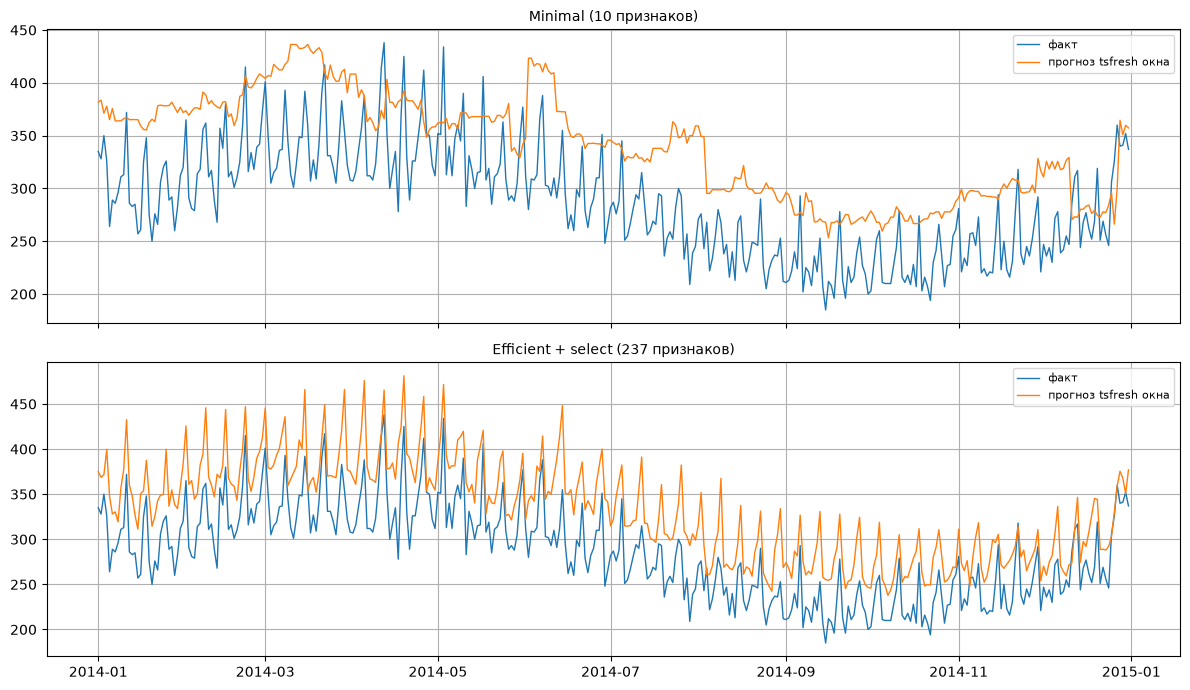

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, res, title in zip(axes, (result_min, result_eff),
                          ("Minimal (10 признаков)", "Efficient + select (237 признаков)")):
    ax.plot(res["y_test"].index, res["y_test"].to_numpy(), label="факт", lw=1.0)
    ax.plot(res["y_test"].index, res["pred"], label="прогноз tsfresh окна", lw=1.0)
    ax.set_title(title, fontsize=10)
    ax.legend(fontsize=8)
fig.tight_layout()

Год вперёд предсказывается «в среднем»: модель повторяет недельный ритм и примерно
угадывает уровень, но промахивается на отдельных всплесках. Наивный прогноз
($t-365$) даёт MAPE 0.1635 — **лучше обоих наборов tsfresh** (0.2002 и 0.1736).
Это важный отрицательный результат: признаки окна, посчитанные на месяце данных,
не содержат того, что нужно знать за год.

## 7. Почему годовой горизонт — ловушка

При $H = 365$ между окном и таргетом лежит целый год. Признаки описывают то, что было
в начале 2014-го, а предсказывать нужно начало 2015-го. Для дневных продаж с медленным
трендом и годовой сезонностью наивный «тот же день год назад» — очень сильный бейзлайн:
он бесплатно переносит и уровень, и сезонность.

Это та же проблема, что в блоке про стратегии прогнозирования: чем короче горизонт,
тем больше пользы от признаков. Проверим это явно.

## 8. Короткий горизонт: окно $W = 28$, $H = 28$ и $H = 7$

Фиксируем окно ровно в 28 точек (`min_timeshift = max_timeshift = 27`), чтобы у всех
строк была одинаковая история, и сравниваем три варианта:

1. **лаги 0…27** — те же 28 значений, что попадают в окно, но поданные как столбцы;
2. **tsfresh Minimal** — 10 агрегатов этого окна;
3. **tsfresh Efficient** — 777 агрегатов.

Плюс версии с календарём дня прогноза (день недели и день года) — без него дневной ряд
не выучить, потому что признаки окна не знают, на какой день недели приходится $t+H$.

In [13]:
t0 = time.perf_counter()
rolled_w = roll_time_series(
    df, column_id="segment", column_sort="timestamp",
    rolling_direction=1, min_timeshift=WINDOW - 1, max_timeshift=WINDOW - 1, n_jobs=0,
)
X_min_w = extract_features(
    rolled_w.drop(columns=["segment"]), default_fc_parameters=MinimalFCParameters(),
    column_id="id", column_sort="timestamp", column_value="target",
    impute_function=impute, show_warnings=False, n_jobs=0,
)
X_eff_w = extract_features(
    rolled_w.drop(columns=["segment"]), default_fc_parameters=EfficientFCParameters(),
    column_id="id", column_sort="timestamp", column_value="target",
    impute_function=impute, show_warnings=False, n_jobs=0,
)
for X in (X_min_w, X_eff_w):
    X.index = pd.DatetimeIndex([ts for _, ts in X.index], name="last_date")
print(f"окон: {len(X_min_w)}, Minimal {X_min_w.shape[1]} признаков, Efficient {X_eff_w.shape[1]}, {time.perf_counter() - t0:.1f} с")

lag_table = pd.DataFrame(
    {f"lag_{k}": s.reindex(X_min_w.index - pd.Timedelta(days=k)).to_numpy() for k in range(WINDOW)},
    index=X_min_w.index,
)


def add_calendar(X: pd.DataFrame, horizon: int) -> pd.DataFrame:
    """День недели и день года дня прогноза — то, чего нет в статистиках окна."""
    out = X.copy()
    out["dow_fut"] = (out.index + pd.Timedelta(days=horizon)).dayofweek
    out["doy_fut"] = (out.index + pd.Timedelta(days=horizon)).dayofyear
    return out

Feature Extraction: 100%|████████████████████████| 2164/2164 [00:51<00:00, 41.78it/s]


окон: 2164, Minimal 10 признаков, Efficient 777, 54.5 с


Сравнение на двух горизонтах, $H = 28$ и $H = 7$. Наивный — значение за 28 дней до дня
прогноза (тот же день недели, четыре недели назад).

In [14]:
rows = {}
for horizon, season in ((28, 28), (7, 7)):
    variants = {
        "лаги 0..27": lag_table,
        "лаги + календарь": add_calendar(lag_table, horizon),
        "tsfresh Minimal": X_min_w,
        "tsfresh Minimal + календарь": add_calendar(X_min_w, horizon),
        "tsfresh Efficient": X_eff_w,
        "tsfresh Efficient + календарь": add_calendar(X_eff_w, horizon),
    }
    for name, X in variants.items():
        res = evaluate(X, horizon, season)
        rows[f"H={horizon} · {name}"] = res
        print(f"H={horizon:3d} {name:30s} {res['признаков']:4d} призн.  "
              f"MAPE={res['MAPE']:.4f}  MAE={res['MAE']:6.1f}  наивный={res['наивный']:.4f}")

summary = pd.DataFrame(
    {name: {"признаков": r["признаков"], "MAPE": round(r["MAPE"], 4),
            "MAE": round(r["MAE"], 1), "наивный MAPE": round(r["наивный"], 4)}
     for name, r in rows.items()}
).T
summary

H= 28 лаги 0..27                       28 призн.  MAPE=0.0974  MAE=  29.7  наивный=0.1365
H= 28 лаги + календарь                 30 призн.  MAPE=0.0642  MAE=  17.8  наивный=0.1365
H= 28 tsfresh Minimal                  10 призн.  MAPE=0.1294  MAE=  39.1  наивный=0.1365
H= 28 tsfresh Minimal + календарь      12 призн.  MAPE=0.0599  MAE=  17.2  наивный=0.1365
H= 28 tsfresh Efficient               777 призн.  MAPE=0.0862  MAE=  26.0  наивный=0.1365
H= 28 tsfresh Efficient + календарь   779 призн.  MAPE=0.0549  MAE=  14.8  наивный=0.1365
H=  7 лаги 0..27                       28 призн.  MAPE=0.1516  MAE=  51.3  наивный=0.2116
H=  7 лаги + календарь                 30 призн.  MAPE=0.0545  MAE=  18.2  наивный=0.2116
H=  7 tsfresh Minimal                  10 призн.  MAPE=0.2281  MAE=  77.6  наивный=0.2116
H=  7 tsfresh Minimal + календарь      12 призн.  MAPE=0.0804  MAE=  26.9  наивный=0.2116
H=  7 tsfresh Efficient               777 призн.  MAPE=0.1995  MAE=  67.7  наивный=0.2116
H=  7 tsfr

,признаков,MAPE,MAE,наивный MAPE
H=28 · лаги 0..27,28.0,0.0974,29.7,0.1365
H=28 · лаги + календарь,30.0,0.0642,17.8,0.1365
H=28 · tsfresh Minimal,10.0,0.1294,39.1,0.1365
H=28 · tsfresh Minimal + календарь,12.0,0.0599,17.2,0.1365
H=28 · tsfresh Efficient,777.0,0.0862,26.0,0.1365
H=28 · tsfresh Efficient + календарь,779.0,0.0549,14.8,0.1365
H=7 · лаги 0..27,28.0,0.1516,51.3,0.2116
H=7 · лаги + календарь,30.0,0.0545,18.2,0.2116
H=7 · tsfresh Minimal,10.0,0.2281,77.6,0.2116
H=7 · tsfresh Minimal + календарь,12.0,0.0804,26.9,0.2116


Что изменилось при переходе с $H = 365$ на короткий горизонт:

- **календарь важнее набора признаков**: при $H = 28$ `Minimal + календарь` даёт MAPE 0.0599
  против 0.0642 у лагов с календарём, а без календаря `Minimal` проигрывает им же — 0.1294;
- **777 признаков не лучше 10**: `Efficient + календарь` = 0.0549, `Minimal + календарь` = 0.0599,
  разница в пределах одного всплеска, а счёт за вычисления различается в сотни раз;
- **при $H = 7$ лаги всё ещё выигрывают**: 0.0545 против 0.0804 у `Minimal` — окно из 28 точек
  само по себе содержит больше информации, чем его сжатые агрегаты;
- **наивный бейзлайн слабый**: 0.1365 при $H = 28$, 0.2116 при $H = 7$ — модель лучше него
  во всех вариантах, кроме tsfresh без календаря.

Главный вывод: **выигрыш даёт не библиотека, а постановка задачи** — короткий горизонт
и календарь. Агрегаты окна сжимают 28 значений в 10–777 чисел, и если в окне главное —
недавние значения (как при $H = 7$), эти значения лучше подать как лаги.

## 9. Цена

Сравним стоимость двух наборов на всём датасете. `Minimal` считается секундами, `Efficient` —
минутами на один ряд.

In [15]:
frames_min, frames_eff = [], []
segments = sorted(data["segment"].unique())[:5]

t0 = time.perf_counter()
for seg in segments:
    part = data[data["segment"] == seg][["segment", "timestamp", "target"]].reset_index(drop=True)
    r = roll_time_series(part, column_id="segment", column_sort="timestamp",
                         rolling_direction=1, min_timeshift=WINDOW - 1, max_timeshift=WINDOW, n_jobs=0)
    frames_min.append(extract_features(
        r.drop(columns=["segment"]), default_fc_parameters=MinimalFCParameters(),
        column_id="id", column_sort="timestamp", column_value="target",
        impute_function=impute, show_warnings=False, n_jobs=0,
    ))
t_min_5 = time.perf_counter() - t0

t0 = time.perf_counter()
for seg in segments[:1]:
    part = data[data["segment"] == seg][["segment", "timestamp", "target"]].reset_index(drop=True)
    r = roll_time_series(part, column_id="segment", column_sort="timestamp",
                         rolling_direction=1, min_timeshift=WINDOW - 1, max_timeshift=WINDOW, n_jobs=0)
    frames_eff.append(extract_features(
        r.drop(columns=["segment"]), default_fc_parameters=EfficientFCParameters(),
        column_id="id", column_sort="timestamp", column_value="target",
        impute_function=impute, show_warnings=False, n_jobs=0,
    ))
t_eff_1 = time.perf_counter() - t0

print(f"Minimal:   {t_min_5:.0f} с на {len(segments)} рядов → ≈ {t_min_5 / len(segments) * 88 / 60:.1f} мин на 88 рядов")
print(f"Efficient: {t_eff_1:.0f} с на 1 ряд    → ≈ {t_eff_1 * 88 / 60:.0f} мин на 88 рядов")

Feature Extraction: 100%|████████████████████████| 2164/2164 [00:52<00:00, 41.57it/s]


Minimal:   6 с на 5 рядов → ≈ 1.7 мин на 88 рядов
Efficient: 54 с на 1 ряд    → ≈ 80 мин на 88 рядов


В тысячу раз дороже — при том, что в глобальной модели это ещё и даст таблицу
на 88 × 2164 строк. 

## 10. Итоги

| Вопрос | Ответ |
|---|---|
| Что даёт tsfresh в окнах | Признак на каждую дату вместо постоянного «паспорта» ряда: модель видит, что происходит сейчас |
| Чем это лучше паспорта | Паспорт описывает ряд, окно — момент; на коротком горизонте окно конкурентоспособно |
| Что важнее набора признаков | Горизонт и календарь: при $H = 28$ `Minimal + календарь` обгоняет лаги |
| Экономит ли `Efficient` | Нет: 777 признаков на 1454 строках только переобучаются, отбор оставляет 237 |
| Чем платим | `Efficient` — около 80 минут на 88 рядов против 2 минут у `Minimal` |
| Утечка | Таргет должен сдвигаться явно на $H$ дней; `shift(-H)` легко ломается при сдвиге индекса |

